# Steam genre recommendation: nine-genre experiments

George's independent implementation following the November 25 meeting.
**Question:** Do recency, latent preferences or transitions improve recommendations
beyond a user's long-term genre mode?

Given positive review history before a cutoff, recommend **one** genre. A hit means
it belongs to a later positively reviewed game's genre set. This is a review-derived
preference proxy, not a directly observed favorite genre or causal satisfaction measure.

**Exploratory evaluation:** Overlapping test events were inspected in the original
ten-genre prototype. Changing the genre vocabulary does not make them an untouched
test. This run selects settings, checkpoints and ensemble weights on validation only.

In [1]:
import json, sys, os
from pathlib import Path
import numpy as np
import pandas as pd
ROOT = Path.cwd() if (Path.cwd() / 'experiments.py').exists() else Path.cwd() / 'george'
ROOT = ROOT.resolve(); sys.path.insert(0, str(ROOT))
OUT = ROOT / 'outputs_v2'
summary = json.loads((OUT / 'summary.json').read_text())
try:
    display_html
except NameError:
    from IPython.display import HTML, Image, display
    def display_html(value): display(HTML(value))
    def display_png(path): display(Image(filename=str(path)))
def table(frame):
    display_html(frame.to_html(index=False, border=0, float_format=lambda x: f'{x:.6f}'))
print('Versions:', summary['versions'])
print('Selected family:', summary['selected_model'])
print(summary['evaluation_status'])

Versions: {'python': '3.12.10', 'numpy': '2.5.5', 'pandas': '3.1.1', 'torch': '2.15.0'}
Selected family: ensemble
Exploratory temporal holdout: overlapping events were inspected in v1; not an untouched confirmatory test.


## 1. Model decision and data cleanup

At least 75% of the 701,884 raw authors have only one review. Start with history
profiles and a shared logistic model, then test latent/sequential models empirically.
No architecture is assumed best in advance.

Inputs are the local reviews, applications, application_genres and genres CSVs.
The manifest does not verify upstream sampling, source URL or license; these remain
team questions. Authors are the user data, not complete user game libraries.

Preserve IDs as strings. Validate dates against a broad year-2000 lower bound,
creation/update order, and the row's extraction timestamp. Deduplicate review IDs
and user–game pairs, keeping the latest state. Keep games, usable genres, and positive
votes. Negative reviews do not imply dislike of every genre and are excluded from
preference counts. Removal counts below are sequential.

Normalize translated genre labels into **Action, Adventure, Casual, Massively
Multiplayer, RPG, Racing, Simulation, Sports and Strategy**. Remove Indie,
release/business-model labels, content descriptors and software/video labels.
**Indie + Action stays as Action.** Drop a game only if no approved genre remains.
Unknown source IDs fail validation; approved rare genres are retained.

All eligible target labels count as correct; no arbitrary primary-genre priority.
The earlier 58.13% result allowed Indie and is not directly comparable.

In [2]:
audit = summary['audit']
table(pd.DataFrame([{'measure': k, 'value': v} for k, v in audit.items() if not isinstance(v, (list, dict))]))
mapping = pd.read_csv(OUT / 'genre_mapping.csv')
table(mapping.groupby('canonical_genre').size().rename('source_label_count').reset_index())
print('Excluded source names:', int(mapping.canonical_genre.isna().sum()))
print('Full mapping: genre_mapping.csv; full-catalog label audit: genre_omission_audit.csv')

measure,value
raw_genre_links,587515
indie_tagged_games_retained,96731
indie_tagged_games_without_gameplay_genre,4476
normalized_game_genre_links,279544
games_with_usable_genres,136259
raw_reviews,1048148
raw_users,701884
invalid_required_fields_removed,0
invalid_or_inconsistent_dates_removed,0
edited_reviews,142383


canonical_genre,source_label_count
Action,16
Adventure,17
Casual,10
Massively Multiplayer,8
RPG,8
Racing,7
Simulation,19
Sports,9
Strategy,14


Excluded source names: 46
Full mapping: genre_mapping.csv; full-catalog label audit: genre_omission_audit.csv


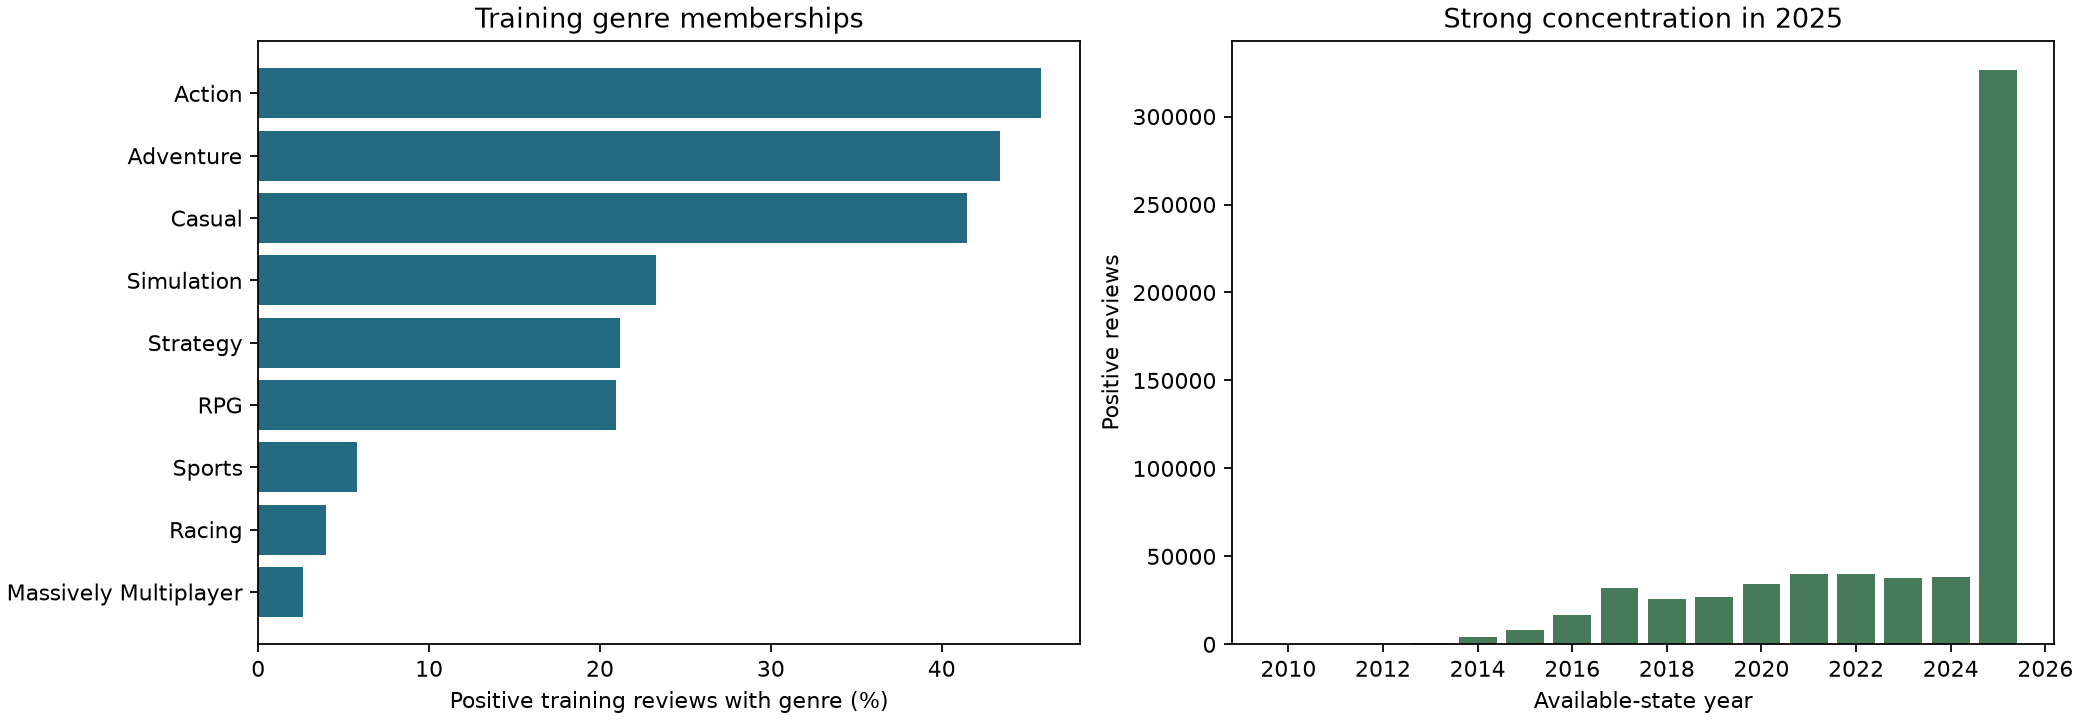

In [3]:
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.mplconfig'))
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
FIG = OUT / 'figures'; FIG.mkdir(exist_ok=True)
dist = pd.read_csv(OUT / 'train_genre_distribution.csv').sort_values('membership_rate')
years = pd.read_csv(OUT / 'reviews_by_year.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')
axes[0].barh(dist.genre, 100 * dist.membership_rate, color='#246b82')
axes[0].set(xlabel='Positive training reviews with genre (%)', title='Training genre memberships')
axes[1].bar(years.year, years.reviews, color='#477a58')
axes[1].set(xlabel='Available-state year', ylabel='Positive reviews', title='Strong concentration in 2025')
fig.savefig(FIG / 'data_overview.png', dpi=160); plt.close(fig)
display_png(FIG / 'data_overview.png')

Multi-genre reviews contribute one count to each genre, so rates need not sum to one.
The fractional-profile ablation distributes one total vote per game while retaining
the same multi-hot targets. Inverse-frequency class weighting is not the default:
it changes the objective and may trade overall Hit@1 for rare-genre coverage.

## 2. Temporal protocol and historical features

Global chronological partitions approximate 70/15/15, with timestamp ties together.
Event time is max(creation, update), since only the final vote state is available.
This predicts later available review states, not play order. Current genre metadata
and missing edit histories prevent a fully historical replay.

Every main model uses frozen histories. Fit on training; tune on validation; refit
on train + validation using selected epoch counts; score test. Simultaneous reviews
form a genre basket, and transitions always originate at a strictly earlier timestamp.

Logistic training creates three disjoint target windows inside fitting data, beginning
at its 40%, 60% and 80% timestamps. Features freeze at each window's start. A target
never enters its own profile. Inputs are long-term genre rates, 90-day-half-life
rates, last genre set, recent global rates, log history length and log review age.
Fixed feature scaling does not require fitting transforms on test data.

In [4]:
table(pd.DataFrame(list(summary['split_counts'].items()), columns=['partition', 'reviews']))
for key in ['event_time_min_utc', 'validation_start_utc', 'test_start_utc', 'event_time_max_utc']:
    print(key, summary[key])
print('Test global mode:', summary['evaluation_global_mode'])

partition,reviews
train,442301
validation,94779
test,94779


event_time_min_utc 2010-11-19T17:15:28+00:00
validation_start_utc 2025-08-14T07:50:18+00:00
test_start_utc 2025-08-24T14:08:49+00:00
event_time_max_utc 2025-09-06T14:37:00+00:00
Test global mode: Action


## 3. Models, implementation and optimization

| Family | Implementation |
|---|---|
| Uniform random | Stable seeded per-user random ranks. |
| Global mode | Most frequent training interaction–genre membership. |
| Recent popularity | Mode in 30/90/180 days before the cutoff. |
| User mode | Most frequent genre in positive user history. |
| Repeat last | Last basket's genre indicators; training-frequency tie break. |
| Recency profile | Weights 2^(-age_days / half_life), half-life 30/90/180 days. |
| Fractional profile | One total vote per reviewed game. |
| Markov-1 | Source-basket transitions smoothed toward global rates; alpha 0.1/1/10. |
| Logistic | PyTorch linear layer with nine outputs, binary cross-entropy with logits. |
| MF-BPR | User and genre factors plus genre bias; no sequence term. |
| FMC-BPR | Factorized previous-to-next genre transitions, no user factor. |
| FPMC-BPR | Preference and transition factors together. |
| Ensemble | Validation-selected weighted ranks from two leading families. |

BPR is an objective, not an architecture or literal SVD. A nine-column genre matrix
has rank at most nine; dimensions 2/4/8 are tested. The loss averages every pair of
present versus absent target genres. An absent genre is not on this event; it is
not assumed to be a lifelong dislike. Previously liked genres remain eligible.

MF/FPMC estimate user factors only with at least two fitting reviews; other users
receive profile fallback. Nobody is removed from evaluation. FMC shares transition
factors. All learned models use the global prior for users with no positive history.
Factor results therefore include explicit hybrid fallback behavior.

Training uses Adam, user-balanced examples, explicit L2, batches up to 8192, a
12-epoch cap and validation patience 3. Staged searches test dimensions, learning
rates and L2 rather than a full Cartesian product. Shortlisted settings run with
seeds 2026/2027/2028; their ranks are averaged. Each seed's epoch uses validation.
Several fits hit the cap; this is a bounded first search, not proof of convergence.

Rank averaging handles incomparable probability/logit scales but discards score
magnitude. Markov-2, game-level Jaccard and deep networks remain future extensions.

In [5]:
validation = pd.read_csv(OUT / 'validation_metrics.csv')
test = pd.read_csv(OUT / 'test_metrics.csv')
table(validation[['model', 'user_hit_at_1', 'user_ndcg_at_3', 'genre_coverage', 'config']])
print('Selected specification:'); print(json.dumps(summary['selected_spec'], indent=2))
seeds = pd.read_csv(OUT / 'seed_metrics.csv')
table(seeds.groupby('model').agg(validation_mean=('user_hit_at_1', 'mean'), validation_std=('user_hit_at_1', 'std'),
                                min_epoch=('best_epoch', 'min'), max_epoch=('best_epoch', 'max')).reset_index())

model,user_hit_at_1,user_ndcg_at_3,genre_coverage,config
uniform_random,0.231127,0.296583,9,"{""kind"": ""random""}"
global_mode,0.474102,0.567385,1,"{""kind"": ""global""}"
recent_popularity,0.474985,0.575463,1,"{""days"": 30, ""kind"": ""recent""}"
user_mode,0.488022,0.573665,9,"{""kind"": ""user""}"
repeat_last,0.486070,0.572125,9,"{""kind"": ""last""}"
recency_profile,0.487822,0.573065,9,"{""half_life"": 180, ""kind"": ""recency""}"
fractional_profile,0.487717,0.573504,9,"{""kind"": ""fractional""}"
markov1,0.480043,0.568508,3,"{""alpha"": 10.0, ""kind"": ""markov1""}"
logistic,0.486469,0.570355,3,"{""dim"": 4, ""kind"": ""logistic"", ""l2"": 0.0001, ""lr"": 0.003, ""max_epochs"": 12, ""seed"": 2026}"
mf,0.487901,0.573511,9,"{""dim"": 8, ""kind"": ""mf"", ""l2"": 0.0001, ""lr"": 0.003, ""max_epochs"": 12, ""seed"": 2026}"


Selected specification:
{
  "family": "ensemble",
  "members": [
    {
      "family": "baseline",
      "config": {
        "kind": "user"
      }
    },
    {
      "family": "mf",
      "configs": [
        {
          "kind": "mf",
          "dim": 8,
          "lr": 0.003,
          "l2": 0.0001,
          "seed": 2026,
          "max_epochs": 12
        },
        {
          "kind": "mf",
          "dim": 8,
          "lr": 0.003,
          "l2": 0.0001,
          "seed": 2027,
          "max_epochs": 12
        },
        {
          "kind": "mf",
          "dim": 8,
          "lr": 0.003,
          "l2": 0.0001,
          "seed": 2028,
          "max_epochs": 12
        }
      ],
      "epochs": [
        11,
        12,
        12
      ]
    }
  ],
  "weights": [
    0.75,
    0.25
  ]
}


model,validation_mean,validation_std,min_epoch,max_epoch
fmc,0.485596,0.000576,3,12
fpmc,0.487424,0.000148,7,12
logistic,0.486398,0.000287,1,1
mf,0.487438,0.000225,11,12


## 4. Evaluation and results

**Primary:** binary Hit@1 averaged within users, then across users. Secondary:
review-weighted Hit@1, user-averaged NDCG@3, genre coverage, per-genre support and
precision/recall, and history cohorts. NDCG@3 evaluates an optional ranking; the
product output remains one genre. Uniform random expected Hit@1 is target-set-size/9.

Paired bootstrap intervals resample users, preserving within-user dependence.
They do not account for shared games, model-selection uncertainty or time shift.

model,user_hit_at_1,review_hit_at_1,user_ndcg_at_3,genre_coverage,refit_seconds,scoring_seconds
uniform_random,0.231429,0.231433,0.298257,9,0.000368,0.034096
global_mode,0.479293,0.477690,0.576467,1,0.000002,0.024901
recent_popularity,0.484412,0.490351,0.584355,1,0.000002,0.027958
user_mode,0.497292,0.502432,0.584733,9,0.000002,0.083295
repeat_last,0.494280,0.497726,0.582740,8,0.000002,0.028387
recency_profile,0.496537,0.501725,0.583902,9,0.000002,0.087431
fractional_profile,0.496644,0.501145,0.584480,9,0.000002,0.090008
markov1,0.489172,0.492493,0.579003,3,0.142125,0.030186
logistic,0.495064,0.499636,0.580377,3,1.697957,0.188344
mf,0.496942,0.501968,0.584860,8,3.186387,0.080407


baseline,lift,ci_low,ci_high,samples,seed
global_mode,0.018010,0.016650,0.019410,1000,2026
user_mode,0.000011,-0.000026,0.000052,1000,2026
recency_profile,0.000766,0.000242,0.001262,1000,2026
mf,0.000361,-0.000068,0.000868,1000,2026


Timings include cache effects and exclude shared data/feature preparation.
Pipeline wall seconds: 61.55
Artifact sizes: {'evaluation_model_bytes': 5599748, 'recommendation_model_bytes': 5866787, 'checkpoint_cache_bytes': 150279111, 'notes': 'Replay uses fixed weights and priors, updates only per-user history, and is not used for selection. Cohorts remain defined at the original cutoff.'}


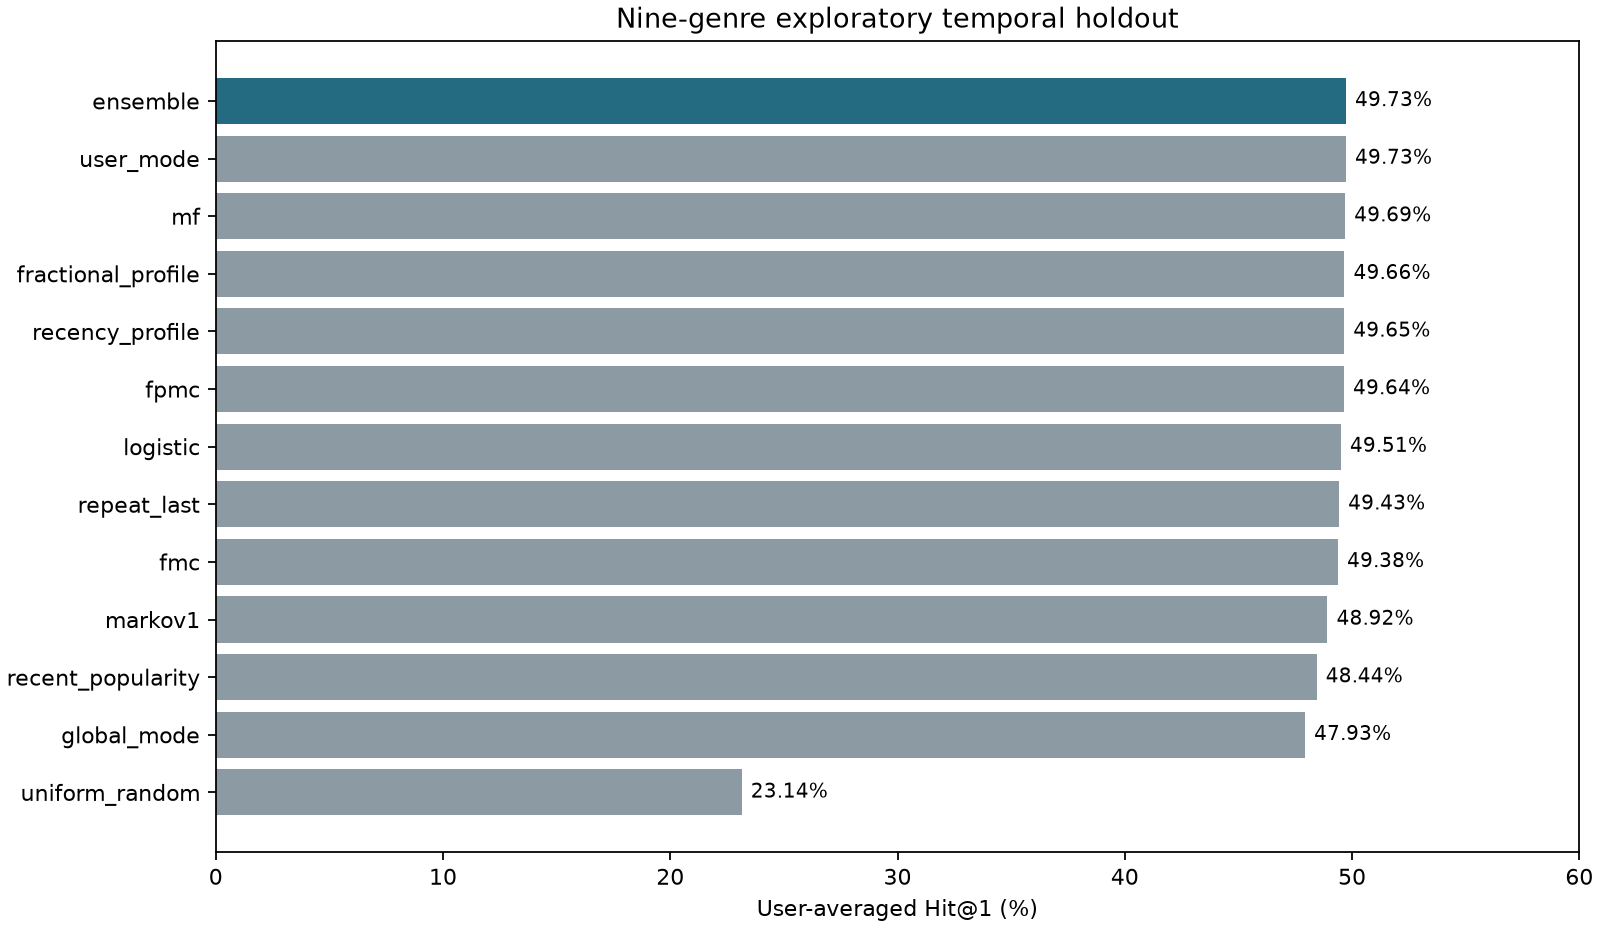

In [6]:
table(test[['model', 'user_hit_at_1', 'review_hit_at_1', 'user_ndcg_at_3', 'genre_coverage', 'refit_seconds', 'scoring_seconds']])
comparisons = json.loads((OUT / 'paired_comparisons.json').read_text())
table(pd.DataFrame([{'baseline': k, **v} for k, v in comparisons.items()]))
print('Timings include cache effects and exclude shared data/feature preparation.')
print('Pipeline wall seconds:', round(summary['wall_seconds'], 2))
print('Artifact sizes:', json.loads((OUT / 'artifact_sizes.json').read_text()))
fig, ax = plt.subplots(figsize=(10, 5.8), layout='constrained')
ordered = test.sort_values('user_hit_at_1')
ax.barh(ordered.model, ordered.user_hit_at_1 * 100,
        color=['#246b82' if n == summary['selected_model'] else '#8c9aa3' for n in ordered.model])
ax.set(xlabel='User-averaged Hit@1 (%)', title='Nine-genre exploratory temporal holdout', xlim=(0, 60))
for i, v in enumerate(ordered.user_hit_at_1): ax.text(v * 100 + .4, i, f'{v:.2%}', va='center', fontsize=9)
fig.savefig(FIG / 'model_comparison.png', dpi=160); plt.close(fig)
display_png(FIG / 'model_comparison.png')

The selected ensemble improves over global popularity, but its difference from
user mode is tiny. Inspect that paired interval before claiming an ensemble win.
Plain user mode is a compelling operational choice; exported predictions follow
the validation-selected model. Added model complexity does not guarantee a gain.

cohort,users,user_hit_at_1,user_ndcg_at_3,model
cold,69788,0.482004,0.571564,ensemble
warm,12156,0.585133,0.660794,ensemble
1-2,8955,0.576403,0.653278,ensemble
3-4,1549,0.599847,0.678210,ensemble
5+,1652,0.618663,0.685202,ensemble


target_reviews,predicted_reviews,genre_recall_at_1,genre_precision_at_1,any_genre_hit_on_this_target_cohort,genre
45275,84049,0.914832,0.492796,0.956422,Action
46475,5303,0.073868,0.647369,0.568865,Adventure
25433,3114,0.062910,0.513809,0.346440,Casual
1799,0,0.000000,NaN,0.721512,Massively Multiplayer
24516,915,0.019905,0.533333,0.476913,RPG
2879,39,0.003126,0.230769,0.411601,Racing
27991,904,0.015827,0.490044,0.294095,Simulation
3052,19,0.000328,0.052632,0.333224,Sports
19852,436,0.011787,0.536697,0.306871,Strategy


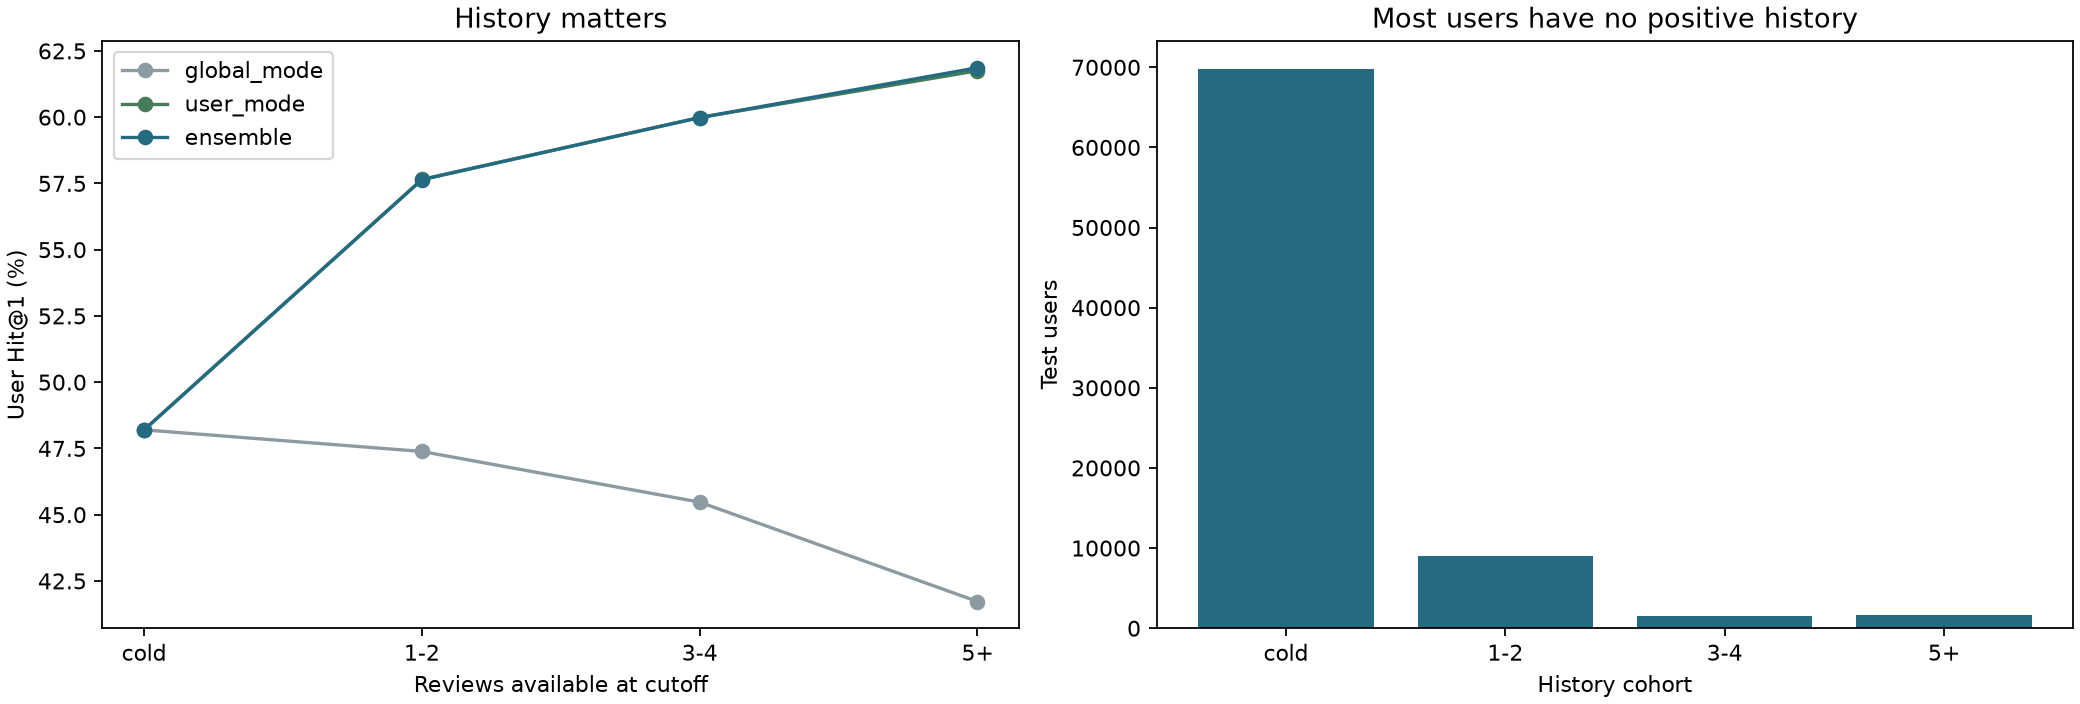

In [7]:
cohorts = pd.read_csv(OUT / 'test_cohorts.csv')
selected = cohorts[cohorts.model.eq(summary['selected_model'])]
table(selected)
per_genre = pd.read_csv(OUT / 'test_per_genre.csv')
table(per_genre[per_genre.model.eq(summary['selected_model'])].drop(columns=['genre_index', 'model']))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), layout='constrained')
groups = ['cold', '1-2', '3-4', '5+']
for model, color in [('global_mode', '#8c9aa3'), ('user_mode', '#477a58'), (summary['selected_model'], '#246b82')]:
    part = cohorts[cohorts.model.eq(model)].set_index('cohort').loc[groups]
    axes[0].plot(groups, part.user_hit_at_1 * 100, marker='o', label=model, color=color)
axes[0].set(xlabel='Reviews available at cutoff', ylabel='User Hit@1 (%)', title='History matters'); axes[0].legend()
axes[1].bar(groups, selected.set_index('cohort').loc[groups].users, color='#246b82')
axes[1].set(xlabel='History cohort', ylabel='Test users', title='Most users have no positive history')
fig.savefig(FIG / 'history_cohorts.png', dpi=160); plt.close(fig)
display_png(FIG / 'history_cohorts.png')

## 5. Robustness and alternative protocol

Minimum history is a cohort, not an exclusion of the full population. Earlier
50–60% and 60–70% time windows are evaluated with fixed selected settings: these
are retrospective diagnostics, not independent nested cross-validation. Unedited
review sensitivity uses the same calendar boundaries and fixed baseline settings.

Sequential replay separately reveals a review only after prediction and updates
per-user history. Simultaneous reviews are revealed together. Learned parameters,
global priors and transition matrices stay frozen; cohorts refer to history at
the original cutoff. No replay result selects the winner.

In [8]:
table(pd.read_csv(OUT / 'development_folds.csv')[['model', 'cutoff_utc', 'users', 'user_hit_at_1']])
table(pd.read_csv(OUT / 'unedited_sensitivity.csv')[['model', 'users', 'reviews', 'user_hit_at_1']])
replay = pd.read_csv(OUT / 'replay_diagnostics.csv')
table(replay.pivot(index='model', columns='protocol', values='user_hit_at_1').reset_index())

model,cutoff_utc,users,user_hit_at_1
global_mode,2025-04-01T22:38:07+00:00,51053,0.457454
user_mode,2025-04-01T22:38:07+00:00,51053,0.473654
recency_profile,2025-04-01T22:38:07+00:00,51053,0.473424
markov1,2025-04-01T22:38:07+00:00,51053,0.469629
ensemble,2025-04-01T22:38:07+00:00,51053,0.473756
global_mode,2025-08-07T03:49:58+00:00,55733,0.468734
user_mode,2025-08-07T03:49:58+00:00,55733,0.478355
recency_profile,2025-08-07T03:49:58+00:00,55733,0.477874
markov1,2025-08-07T03:49:58+00:00,55733,0.474025
ensemble,2025-08-07T03:49:58+00:00,55733,0.478341


model,users,reviews,user_hit_at_1
global_mode,74156,84915,0.477416
user_mode,74156,84915,0.494469
repeat_last,74156,84915,0.491309
markov1,74156,84915,0.486722


protocol,model,frozen,sequential_replay
,ensemble,0.497303,0.502500
,fmc,0.493803,0.498015
,fpmc,0.496429,0.501652
,fractional_profile,0.496644,0.501757
,global_mode,0.479293,0.479293
,logistic,0.495064,0.498790
,markov1,0.489172,0.492815
,mf,0.496942,0.501802
,recency_profile,0.496537,0.501802
,recent_popularity,0.484412,0.484412


## 6. Reproduction and inference

Run `experiments.py`, `diagnostics.py`, `verify.py`, then `build_report.py` with the
local virtual environment. `experiment_config.json`, `requirements-lock.txt`, code/data
hashes, checkpoint metadata and seed results record the run. The evaluation model
fits train + validation; the deployment model refits all positive data only after
evaluation. Every original identifiable user receives a genre.

Numeric NPZ snapshots need no pickle. Unknown IDs get global fallback. Incorporating
new history requires rebuilding the batch snapshot; this is not an online service.
Model scores are ranking values, not calibrated enjoyment probabilities.

In [9]:
from models import SnapshotRecommender
model = SnapshotRecommender.load(OUT / 'recommendation_model.npz')
table(model.predict(['new_user']))
print(f"Users served: {summary['recommendation_users']:,}; no positive history: {summary['recommendation_cold_users']:,}")
print(json.dumps(json.loads((OUT / 'verification.json').read_text()), indent=2))

author_steamid,recommended_genre,history_count,score
new_user,Action,0,0.463182


Users served: 701,884; no positive history: 242,836
{
  "status": "passed",
  "checks": [
    "nine-genre vocabulary and unique catalog links",
    "unique review IDs and user-game pairs",
    "strict chronological splits and timestamp ties",
    "cleanup row conservation",
    "one valid recommendation per original user",
    "evaluation and deployment histories fit only their respective partitions",
    "saved-model predictions reproduce all exported recommendations",
    "selected model metrics recomputed from saved scores",
    "training-only global prior",
    "unknown-user fallback",
    "source hash matches executed results",
    "diagnostic frozen scores reproduce main experiment"
  ],
  "users": 701884,
  "test_reviews": 94779
}


## 7. Tradeoffs, related work and assignment status

- Gameplay genres are more interpretable than Indie, but exclude games lacking
  any approved label and still simplify diverse interests into broad categories.
- Review sampling and positive-only feedback can bias results; there is no full
  ownership/play history. Lifetime playtime/ownership totals and target review
  text are not predictive inputs because of availability/leakage concerns.
- Update time is conservative for final-vote availability, but is not play order.
  Snapshot genres and missing edit histories limit historical validity.
- Shared logistic coefficients support sparse histories. User factors require
  fallback behavior, and the bounded search does not establish universal rankings.
- An ensemble adds storage/inference cost for little improvement over user mode.
  Rank averaging sacrifices score magnitude to avoid mixing incompatible scales.
- A genuinely untouched final test needs new data or an uninspected period.

[BPR (Rendle et al., 2009)](https://proceedings.mlr.press/r7/rendle09a.html)
motivates pairwise ranking. Our nine-genre adaptation enumerates all event-specific
positive/negative pairs rather than sampling a large item space.
[FPMC (Rendle et al., 2010)](https://archives.iw3c2.org/www2010/pub/pdfs/RendleFreudenthaler2010-FPMC.pdf)
combines preference and transition factors. Our genre baskets, sparse-user fallback
and protocol differ from the original benchmark; published scores are not comparable.
[PyTorch BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html)
supplies the logistic model's multi-label training loss.

The assignment PDF requests task definition, EDA, modeling, evaluation, related
work, an HTML notebook, a roughly 20-minute recorded presentation and peer grading.
This report supports the technical sections. The team still needs verified data
provenance, integrated group findings, the recording and real video URL, and peer
grading. No video or final submission has been fabricated.